In [39]:
from autogradWN import Tensor, MLP, Dense, SoftmaxCCE, MSE, SGD, Adam
import numpy as np
from sklearn.datasets import load_iris, fetch_openml
import matplotlib.pyplot as plt

In [40]:
from sklearn.model_selection import train_test_split

# Baixando os datasets
iris = load_iris()
boston = fetch_openml(name="boston", version=1, as_frame=False)

# Divisão treino/teste (80/20)
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    iris.data, iris.target,
    test_size=0.2, stratify=iris.target, random_state=42
)

X_boston_train, X_boston_test, y_boston_train, y_boston_test = train_test_split(
    np.asarray(boston.data, dtype=float),
    np.asarray(boston.target, dtype=float).reshape(-1, 1),
    test_size=0.2, random_state=42
)

# Convertendo para tensores
def criar_tensor(dados):
    tensor = Tensor(dados.shape)
    tensor.peso = dados
    return tensor

X_iris_train = criar_tensor(X_iris_train)
X_iris_test = criar_tensor(X_iris_test)
y_iris_train = criar_tensor(y_iris_train)
y_iris_test = criar_tensor(y_iris_test)

X_boston_train = criar_tensor(X_boston_train)
X_boston_test = criar_tensor(X_boston_test)
y_boston_train = criar_tensor(y_boston_train)
y_boston_test = criar_tensor(y_boston_test)

In [41]:
print(X_iris_train.peso.shape)    # (120, 4)
print(y_iris_train.peso.shape)    # (120,)

print(X_boston_train.peso.shape)  # (404, 13)
print(y_boston_train.peso.shape)  # (404, 1)

(120, 4)
(120,)
(404, 13)
(404, 1)


In [42]:
print(X_iris_train)

[[4.4 2.9 1.4 0.2]
 [4.9 2.5 4.5 1.7]
 [6.8 2.8 4.8 1.4]
 [4.9 3.1 1.5 0.1]
 [5.5 2.5 4.  1.3]
 [6.3 2.5 5.  1.9]
 [5.6 2.7 4.2 1.3]
 [6.3 2.8 5.1 1.5]
 [7.7 3.  6.1 2.3]
 [7.7 3.8 6.7 2.2]
 [7.6 3.  6.6 2.1]
 [6.  2.9 4.5 1.5]
 [5.  2.  3.5 1. ]
 [5.8 2.7 4.1 1. ]
 [5.8 2.6 4.  1.2]
 [4.7 3.2 1.6 0.2]
 [5.1 3.8 1.5 0.3]
 [6.7 2.5 5.8 1.8]
 [6.4 3.1 5.5 1.8]
 [5.4 3.4 1.5 0.4]
 [6.3 2.5 4.9 1.5]
 [5.1 3.8 1.6 0.2]
 [7.9 3.8 6.4 2. ]
 [5.  3.  1.6 0.2]
 [5.5 2.4 3.7 1. ]
 [6.3 2.9 5.6 1.8]
 [6.4 2.7 5.3 1.9]
 [5.  3.4 1.6 0.4]
 [5.6 2.8 4.9 2. ]
 [5.  3.5 1.3 0.3]
 [5.1 3.7 1.5 0.4]
 [6.1 2.8 4.  1.3]
 [6.1 3.  4.6 1.4]
 [5.7 4.4 1.5 0.4]
 [6.9 3.1 5.4 2.1]
 [6.2 3.4 5.4 2.3]
 [5.7 2.6 3.5 1. ]
 [5.2 2.7 3.9 1.4]
 [6.7 3.3 5.7 2.5]
 [5.9 3.2 4.8 1.8]
 [4.6 3.4 1.4 0.3]
 [7.  3.2 4.7 1.4]
 [5.4 3.9 1.3 0.4]
 [7.4 2.8 6.1 1.9]
 [4.9 3.  1.4 0.2]
 [5.1 3.5 1.4 0.3]
 [5.8 2.7 5.1 1.9]
 [5.  3.2 1.2 0.2]
 [4.5 2.3 1.3 0.3]
 [4.8 3.  1.4 0.1]
 [4.8 3.  1.4 0.3]
 [5.6 2.9 3.6 1.3]
 [6.3 3.3 6.

In [43]:
print(X_boston_train)

[[1.50234e+01 0.00000e+00 1.81000e+01 ... 2.02000e+01 3.49480e+02
  2.49100e+01]
 [6.27390e-01 0.00000e+00 8.14000e+00 ... 2.10000e+01 3.95620e+02
  8.47000e+00]
 [3.46600e-02 3.50000e+01 6.06000e+00 ... 1.69000e+01 3.62250e+02
  7.83000e+00]
 ...
 [1.50100e-02 8.00000e+01 2.01000e+00 ... 1.70000e+01 3.90940e+02
  5.99000e+00]
 [1.11604e+01 0.00000e+00 1.81000e+01 ... 2.02000e+01 1.09850e+02
  2.32700e+01]
 [2.28760e-01 0.00000e+00 8.56000e+00 ... 2.09000e+01 7.08000e+01
  1.06300e+01]]


# Treinando iris

In [ ]:
modelo_iris = MLP(
    (Dense(4, 32), True, "reLU"),
    (Dense(32, 32), True, "reLU"),
    (Dense(32, 3), True, "linear")
)

otimizador = SGD(modelo_iris, 0.0001)

epocas = 100

historico_treino = []
historico_test = []
historico_acc_treino = []
historico_acc_test = []


for epoca in range(epocas):
    # treino
    total_loss = []
    acertos_treino = []
    for i in range(X_iris_train.peso.shape[0]):
        logits = modelo_iris(X_iris_train[i:i+1])
        loss = SoftmaxCCE(y_iris_train[i], logits)
        
        acertos_treino.append(int(np.argmax(logits.peso) == y_iris_train.peso[i]))
        
        loss.backward()
        
        otimizador.passo()
        
        modelo_iris.zerar_gradiente()
        
        total_loss.append(float(loss.peso))
    
    # Validação
    validation_loss = []
    acertos_test = []
    for i in range(X_iris_test.peso.shape[0]):
        logits = modelo_iris(X_iris_test[i:i+1])
        loss = SoftmaxCCE(y_iris_test[i], logits)
        
        acertos_test.append(int(np.argmax(logits.peso) == y_iris_test.peso[i]))
    
        
        validation_loss.append(float(loss.peso)) 
    
    historico_treino.append(np.mean(total_loss))
    historico_test.append(np.mean(validation_loss))
    historico_acc_treino.append(np.mean(acertos_treino))   
    historico_acc_test.append(np.mean(acertos_test)) 
    
    print(f"Epoca: {epoca}", f"Loss: {np.mean(total_loss):.3f}", f"Val_Loss: {np.mean(validation_loss):.3f}")      

Epoca: 0 Loss: 2.037 Val_Loss: 1.609
Epoca: 1 Loss: 1.463 Val_Loss: 1.353
Epoca: 2 Loss: 1.282 Val_Loss: 1.208
Epoca: 3 Loss: 1.161 Val_Loss: 1.100
Epoca: 4 Loss: 1.069 Val_Loss: 1.014
Epoca: 5 Loss: 0.994 Val_Loss: 0.944
Epoca: 6 Loss: 0.932 Val_Loss: 0.886
Epoca: 7 Loss: 0.880 Val_Loss: 0.837
Epoca: 8 Loss: 0.836 Val_Loss: 0.795
Epoca: 9 Loss: 0.798 Val_Loss: 0.758
Epoca: 10 Loss: 0.764 Val_Loss: 0.726
Epoca: 11 Loss: 0.735 Val_Loss: 0.698
Epoca: 12 Loss: 0.709 Val_Loss: 0.673
Epoca: 13 Loss: 0.685 Val_Loss: 0.651
Epoca: 14 Loss: 0.664 Val_Loss: 0.630
Epoca: 15 Loss: 0.645 Val_Loss: 0.612
Epoca: 16 Loss: 0.627 Val_Loss: 0.595
Epoca: 17 Loss: 0.611 Val_Loss: 0.580
Epoca: 18 Loss: 0.596 Val_Loss: 0.566
Epoca: 19 Loss: 0.582 Val_Loss: 0.553
Epoca: 20 Loss: 0.569 Val_Loss: 0.541
Epoca: 21 Loss: 0.557 Val_Loss: 0.529
Epoca: 22 Loss: 0.546 Val_Loss: 0.519
Epoca: 23 Loss: 0.535 Val_Loss: 0.509
Epoca: 24 Loss: 0.525 Val_Loss: 0.500
Epoca: 25 Loss: 0.516 Val_Loss: 0.491
Epoca: 26 Loss: 0.507 

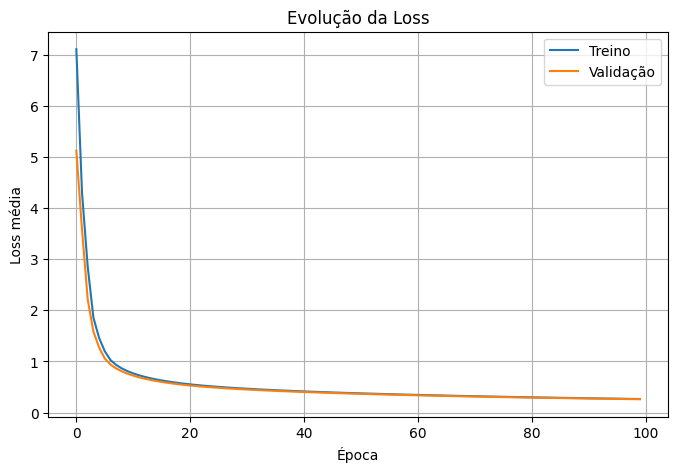

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(historico_treino, label="Treino")
plt.plot(historico_val, label="Validação")

plt.xlabel("Época")
plt.ylabel("Loss média")
plt.title("Evolução da Loss")
plt.legend()
plt.grid(True)

plt.show()
